# 03 - Ensembles

Phase P4 of the [implementation plan](../docs/plan/01-rr2-implementation-plan.md).
Fits the two ensembles compared in RQ3 on the official train split and checks the per-member contributions used by P5/P6.

- **RF:** `RandomForestClassifier`, 100 trees, `max_depth=5`, `max_features=0.3` per split.
- **LR:** `BaggingClassifier` of 100 `StandardScaler + LogisticRegression` members, `max_features=0.5` (each member sees half of the encoded columns).

Both use `random_state=42`; later notebooks rebuild them with `ensemble.build()`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

from project_acl import ensemble
from project_acl.preprocess import encode, read, split

sns.set_theme(style="white", context="notebook")
FIG = Path("../docs/figures")
FIG.mkdir(exist_ok=True)

df = read()
X, y, source = encode(df)
X_tr, X_te, y_tr, y_te = split(X, y, df)
X_te, y_te = X_te.to_numpy(float), y_te.to_numpy()
models = ensemble.build(X_tr, y_tr)
print(X_tr.shape, X_te.shape, "| positive rate test:", y_te.mean().round(3))

[16:17:40] INFO     fitted RF: 100 members                                                           ]8;id=11480591;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py\ensemble.py]8;;\:]8;id=11480592;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py#41\41]8;;\

[16:17:46] INFO     fitted LR: 100 members                                                           ]8;id=11480597;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py\ensemble.py]8;;\:]8;id=11480598;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py#41\41]8;;\

(32561, 104) (16281, 104) | positive rate test: 0.236


## 1. Performance

Ensemble scores vs. the distribution of single-member scores on the test split. Majority class baseline: always predict `<=50K`.

In [2]:
proba = {name: ensemble.member_proba(m, X_te) for name, m in models.items()}
rows = []
for name, m in models.items():
    pred = m.predict(X_te)
    rows.append((name, "ensemble", accuracy_score(y_te, pred), f1_score(y_te, pred)))
    for p in proba[name]:
        rows.append((name, "member", accuracy_score(y_te, p > 0.5), f1_score(y_te, p > 0.5, zero_division=0)))
scores = pd.DataFrame(rows, columns=["model", "level", "accuracy", "F1"])
print("majority baseline accuracy:", round(1 - y_te.mean(), 3))
scores.groupby(["model", "level"])[["accuracy", "F1"]].describe().loc[:, (slice(None), ["mean", "min", "max"])].round(3)

majority baseline accuracy: 0.764


accuracy                   F1              
                   mean    min    max   mean    min    max
model level                                               
LR    ensemble    0.850  0.850  0.850  0.629  0.629  0.629
      member      0.829  0.783  0.851  0.579  0.387  0.650
RF    ensemble    0.852  0.852  0.852  0.625  0.625  0.625
      member      0.839  0.809  0.851  0.584  0.406  0.649

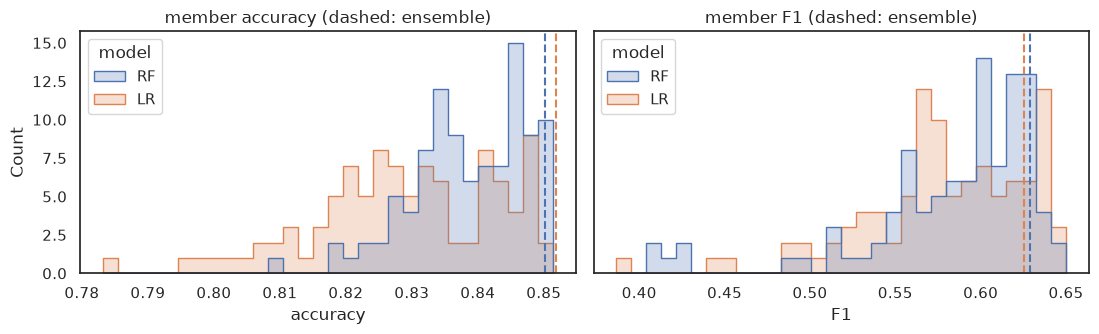

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
members = scores[scores.level == "member"]
for ax, metric in zip(axes, ["accuracy", "F1"]):
    sns.histplot(members, x=metric, hue="model", bins=30, ax=ax, element="step")
    for (name, s), c in zip(scores[scores.level == "ensemble"].groupby("model"), sns.color_palette()):
        ax.axvline(s[metric].iloc[0], color=c, ls="--", label=f"{name} ensemble")
    ax.set_title(f"member {metric} (dashed: ensemble)")
plt.tight_layout()
plt.gcf().savefig(FIG / "member_performance.png", dpi=200, bbox_inches="tight")

## 2. Member diversity

Pairwise prediction disagreement: share of test samples on which two members vote differently. If members
rarely disagree, concept agreement in P5 is trivially high (plan, risk "Similar LR members").

In [4]:
def pairwise_disagreement(p):
    votes = (p > 0.5).astype(float)
    d = (votes[:, None, :] != votes[None, :, :]).mean(axis=2)
    return d[np.triu_indices(len(votes), k=1)]

div = pd.DataFrame([(name, d) for name in models for d in pairwise_disagreement(proba[name])], columns=["model", "disagreement"])
print(div.groupby("model")["disagreement"].describe().round(3))

votes1 = {name: (p > 0.5).mean(axis=0) for name, p in proba.items()}
margin = pd.DataFrame({name: np.abs(2 * v - 1) for name, v in votes1.items()})
print("\nshare of test samples with unanimous vote:")
print((margin == 1).mean().round(3))

        count   mean    std    min    25%    50%    75%    max
model                                                         
LR     4950.0  0.101  0.031  0.019  0.078  0.100  0.126  0.189
RF     4950.0  0.071  0.032  0.005  0.046  0.067  0.095  0.187

share of test samples with unanimous vote:
RF    0.620
LR    0.505
dtype: float64


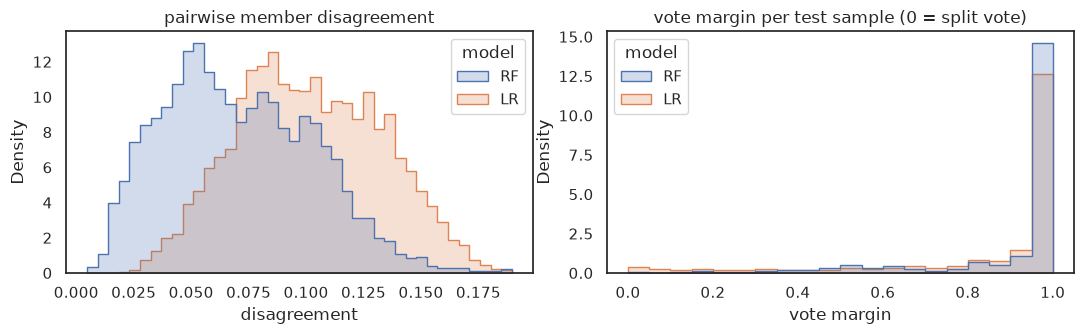

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(div, x="disagreement", hue="model", bins=40, ax=axes[0], element="step", stat="density", common_norm=False)
axes[0].set_title("pairwise member disagreement")
sns.histplot(margin.melt(var_name="model", value_name="vote margin"), x="vote margin", hue="model", bins=20,
             ax=axes[1], element="step", stat="density", common_norm=False)
axes[1].set_title("vote margin per test sample (0 = split vote)")
plt.tight_layout()
plt.gcf().savefig(FIG / "member_diversity.png", dpi=200, bbox_inches="tight")

## 3. Per-member contributions

`member_contributions(model, X)` returns `phi[member, sample, feature]`:
- tree members: Saabas path decomposition in log-odds space; node probabilities are Laplace-smoothed
  (`(p n + 1) / (n + 2)`) so pure nodes stay finite; rows sum to `logit_m(leaf) - logit_m(root)`;
- LR members: `coef_f * (x_f - mean_f)` on standardised inputs in log-odds space; features outside the member's subset are 0.

Both are in log-odds, so raw contributions are on the same scale across ensembles.

The sum checks below are the same as in `tests/test_core.py`, on the full test split.

In [6]:
phi = {name: ensemble.member_contributions(m, X_te) for name, m in models.items()}
for name, model in models.items():
    err = 0
    for k, (m, f) in enumerate(ensemble.members(model)):
        if name == "RF":
            logits = ensemble.node_logit(m)
            expected = logits[m.apply(X_te)] - logits[0]
        else:
            expected = m.decision_function(X_te[:, f]) - m.decision_function(m[0].mean_[None])[0]  # logit(p) saturates
        err = max(err, np.abs(phi[name][k].sum(axis=1) - expected).max())
    print(f"{name}: phi {phi[name].shape}, {phi[name].nbytes / 1e6:.0f} MB, max |sum - expected| = {err:.1e}")

RF: phi (100, 16281, 104), 677 MB, max |sum - expected| = 8.4e-07


LR: phi (100, 16281, 104), 677 MB, max |sum - expected| = 1.2e-05


Scale check: total `|phi|` per member and sample, in log-odds. Same order of magnitude for both ensembles.

In [7]:
pd.DataFrame({name: np.abs(ph).sum(axis=2).ravel() for name, ph in phi.items()}).describe(percentiles=[0.5, 0.99]).round(2)

,RF,LR
count,1628100.00,1628100.00
mean,2.90,4.27
std,1.23,2.06
min,1.14,1.30
50%,2.70,4.03
99%,7.98,8.63
max,14.72,43.34


Mean absolute contribution per source feature (encoded columns summed back to their feature), as a share of the
member's total. A first look only; P5 aggregates by ontology concept.

,RF,LR
marital-status,0.295,0.222
relationship,0.191,0.215
education-num,0.150,0.077
capital-gain,0.114,0.072
age,0.085,0.031
hours-per-week,0.064,0.023
occupation,0.040,0.129
education,0.026,0.083
capital-loss,0.019,0.012
sex,0.013,0.059


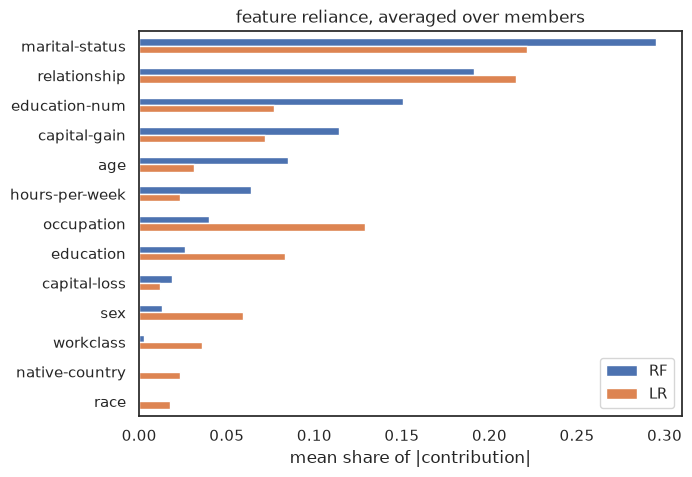

In [8]:
cols = np.array([source[c] for c in X.columns])
feats = sorted(set(cols))
share = {}
for name, ph in phi.items():
    a = np.abs(ph).mean(axis=1)  # (members, columns)
    by_feat = np.stack([a[:, cols == f].sum(axis=1) for f in feats], axis=1)
    share[name] = (by_feat / by_feat.sum(axis=1, keepdims=True)).mean(axis=0)
share = pd.DataFrame(share, index=feats).sort_values("RF", ascending=False)

ax = share.plot.barh(figsize=(7, 5))
ax.invert_yaxis()
ax.set_xlabel("mean share of |contribution|")
ax.set_title("feature reliance, averaged over members")
share.round(3)

## Findings

- **Performance.** RF ensemble: accuracy 0.852, F1 0.625. LR ensemble: 0.850, F1 0.629 (majority baseline 0.764).
  Members are equally strong (mean member F1 0.58 for both). Trees use depth 5 and 30% of the columns per split;
  depth 4 with the default `sqrt` gave members that almost never predicted `>50K`.
- **Diversity.** Mean pairwise disagreement is 0.07 (RF) and 0.10 (LR); 62% (RF) and 51% (LR) of test samples get a
  unanimous vote. Stronger trees agree more, but both ensembles keep enough disagreement for RQ1/RQ2.
  LR members are not near identical, so `max_features=0.5` did its job.
- **Contributions.** Both member types are in log-odds space; tree node probabilities are Laplace-smoothed so pure
  leaves stay finite. Decompositions are exact up to float32 rounding (max error 8e-7 RF, 1e-5 LR), and total `|phi|`
  per member is on the same scale (median about 2.7 RF vs 4.0 LR).
- **First reliance view.** Both ensembles lean most on `marital-status` and `relationship` (the `Family` concept;
  `relationship` is also in the `ProtectedAttribute` view). RF relies more on `education-num`, `capital-gain` and `age`;
  LR spreads weight over `occupation`, `education`, `sex`, `workclass`, `native-country`. P5 checks this at concept level.